In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import json
from req_functions_from_ApproxSP import *
from tqdm import tqdm
from generate_profiles import *
from euclidean import *
from mallows import *
from AccompliceManipulation import *
from impartial import *

In [13]:
import pandas as pd

**Mallows MA**

In [ ]:

def generate_MA(num_agents):
    votes_left = []
    votes_right = []

    for i in range(num_agents):
        row_left = [(i + j) % num_agents for j in range(num_agents)]
        votes_left.append(row_left)

        row_right = [(i - j) % num_agents for j in range(num_agents)]
        votes_right.append(row_right)

    return votes_left, votes_right

def generate_mallows_MA_votes(num_agents, phi_m, phi_w, **kwargs):
    """ Mallows on top of Asymmetric instance """
    
    votes_left_array, votes_right_array = generate_MA(num_agents)
    
    # Apply Mallows
    votes_left_array = mallows_votes(votes_left_array, phi_m)
    votes_right_array = mallows_votes(votes_right_array, phi_w)
    
    # No need for .tolist()
    votes_left = votes_left_array
    votes_right = votes_right_array

 
    j = 0
    for row in votes_left:
        for i in range(len(row)):
            votes_left[j][i] += 1
        j+=1
    j = 0
    for row in votes_right:
        for i in range(len(row)):
            votes_right[j][i] += 1
        j += 1
 
 
    return [votes_left, votes_right]
def mallows_vote(vote, phi):
    num_candidates = len(vote)
    raw_vote = generate_mallows_votes(1, num_candidates, phi=phi, weight=0)[0]
    new_vote = [0] * len(vote)
    for i in range(num_candidates):
        new_vote[raw_vote[i]] = vote[i]
    return new_vote
 
 
def mallows_votes(votes, phi):
    for i in range(len(votes)):
        votes[i] = mallows_vote(votes[i], phi)
    return votes
 
def generate_mallows_votes(num_voters, num_candidates, phi=0.5, weight=0, **kwargs):
    if phi is None:
        logging.warning('phi is not defined')
    insertion_probabilites_list = []
    for i in range(1, num_candidates):
        insertion_probabilites_list.append(computeInsertionProbas(i, phi))
    V = []
    for i in range(num_voters):
        vote = mallowsVote(num_candidates, insertion_probabilites_list)
        if weight > 0:
            probability = np.random.random()
            if probability <= weight:
                vote.reverse()
        V += [vote]
    return V
 

def computeInsertionProbas(i, phi):
    probas = (i + 1) * [0]
    for j in range(i + 1):
        probas[j] = pow(phi, (i + 1) - (j + 1))
    return probas


def mallowsVote(m, insertion_probabilites_list):
    vote = [0]
    for i in range(1, m):
        index = weighted_choice(insertion_probabilites_list[i - 1])
        vote.insert(index, i)
    return vote


def weighted_choice(choices):
    total = 0
    for w in choices:
        total = total + w
    r = np.random.uniform(0, total)
    upto = 0.0
    for i, w in enumerate(choices):
        if upto + w >= r:
            return i
        upto = upto + w
    assert False, "Shouldn'process_id get here"

In [11]:
##Mallows MA

data_MA = []
numberMA = []
numberMA_pairs = []
n=30
phi_list=[0, 0.2, 0.4, 0.6, 0.8, 1]
for phi1 in tqdm(phi_list):
    number_phi = []
    number_phi_pairs = []
    for phi2 in tqdm(phi_list):
        count = []
        count_pairs = []
        ct = []
        for samples in range (500):
            count_woman = 0
            cnt_pairs = 0
            pref=generate_mallows_MA_votes(n, phi1, phi2)
            mpref=pref[0]
            wpref=pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                cnt = 0
                for accomplice in range(1, n+1):
                    result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
                    if result [0]!= matching:
                        cnt = cnt+1
                if cnt >= 1:
                    count_woman += 1
                    cnt_pairs += cnt
            count_pairs.append(cnt_pairs)
            count.append(count_woman)
            data_MA.append([phi1, phi2, json.dumps(mpref), json.dumps(wpref), samples, count_woman, cnt_pairs])
        if len(count) > 0: 
            number_phi.append(sum(count) / len(count))
            number_phi_pairs.append(sum(count_pairs) / len(count_pairs))
        else:
            number_phi.append(0)
            number_phi_pairs.append(0)
    numberMA.append(number_phi)
    numberMA_pairs.append(number_phi_pairs) 
print(numberMA)
print(numberMA_pairs) 

100%|██████████| 6/6 [46:39<00:00, 466.62s/it]

[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.004, 0.058, 0.418, 1.626, 3.35], [0.0, 0.044, 0.356, 1.26, 2.774, 5.436], [0.854, 0.22, 0.928, 1.806, 2.874, 6.29], [2.688, 2.216, 2.162, 2.786, 4.066, 6.664], [6.69, 6.784, 7.074, 7.022, 6.582, 6.328]]
[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.004, 0.106, 0.982, 5.966, 22.518], [0.0, 0.044, 0.628, 3.454, 14.226, 33.196], [2.45, 0.37, 1.688, 4.8, 14.272, 41.102], [11.03, 9.718, 7.672, 10.036, 18.21, 39.456], [41.71, 44.308, 43.502, 42.3, 36.668, 35.334]]


In [14]:
df2 = pd.DataFrame(data_MA, columns=["phi_m", "phi_w", "mpref", "wpref", "sample", "count_woman", "count_pairs"])
df2.to_csv('mallows_MA_accomplice.csv', index=False)

**Euclidean Mallows**

In [2]:
## Euclidean Mallows Accomplice for d = 2

data_EM = []
numberEM = []
numberEM_pairs = []
n=30
phi_list=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
for phi1 in tqdm(phi_list):
    number_phi = []
    number_phi_pairs = []
    for phi2 in tqdm(phi_list):
        count=[]
        count_pairs = []
        ct=[]
        for samples in range (500):
            count_woman = 0
            cnt_pairs = 0
            pref=generate_mallows_euclidean_votes(n, phi1, phi2)
            mpref=pref[0]
            wpref=pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                cnt=0
                for accomplice in range(1, n+1):
                    result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
                    if result [0]!= matching:
                        cnt = cnt+1
                if cnt >= 1:
                    count_woman += 1
                    cnt_pairs += cnt
            count_pairs.append(cnt_pairs)
            count.append(count_woman)
            data_EM.append([phi1, phi2, json.dumps(mpref), json.dumps(wpref), samples, count_woman, cnt_pairs])
        if len(count)>0:
            number_phi.append(sum(count) / len(count))
            number_phi_pairs.append(sum(count_pairs) / len(count_pairs))
        else:
            number_phi.append(0)
            number_phi_pairs.append(0)
    numberEM.append(number_phi)
    numberEM_pairs.append(number_phi_pairs)
print(numberEM)
print(numberEM_pairs)

100%|██████████| 6/6 [3:52:22<00:00, 2323.67s/it]

[[0.0, 0.076, 0.316, 0.692, 1.604, 4.714], [0.064, 0.18, 0.37, 0.894, 1.766, 4.642], [0.238, 0.368, 0.546, 0.936, 1.804, 5.188], [0.48, 0.63, 0.914, 1.308, 2.13, 5.092], [1.252, 1.33, 1.424, 2.072, 3.082, 6.112], [5.194, 5.382, 5.398, 5.842, 6.15, 7.018]]
[[0.0, 0.136, 0.464, 1.602, 6.804, 30.846], [0.08, 0.248, 0.662, 2.31, 8.156, 31.344], [0.394, 0.63, 1.01, 2.374, 8.002, 32.954], [1.07, 1.49, 2.356, 4.012, 9.134, 32.368], [3.876, 4.676, 4.898, 8.1, 14.338, 36.276], [29.552, 29.126, 29.666, 32.74, 34.398, 36.906]]


In [4]:
df2 = pd.DataFrame(data_EM, columns=["phi_m", "phi_w", "mpref", "wpref", "sample", "count_woman", "count_pairs"])
df2.to_csv('euclidean_mallows_accomplice.csv', index=False)

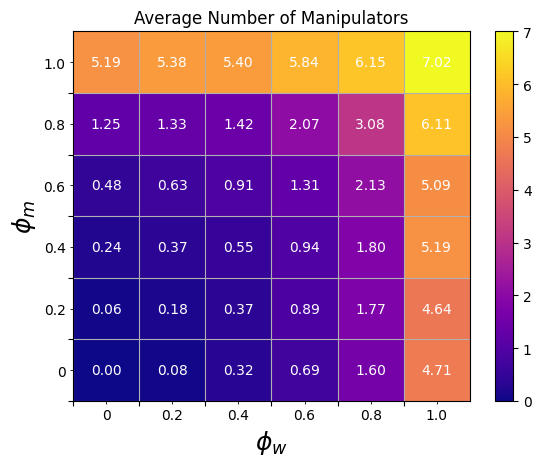

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0] 
    
w_number = np.array(numberEM)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=7))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Average Number of Manipulators')
plt.grid(True)

plt.savefig("accomplice_Euclidean_Mallows.pdf", format='pdf')
plt.show()

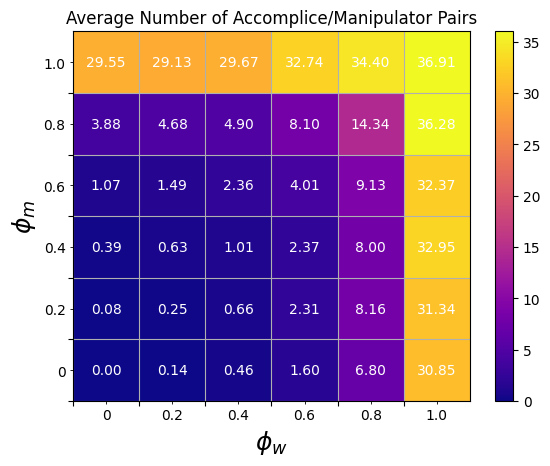

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors #udsfb

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0] 
    
w_number = np.array(numberEM_pairs)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=36))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Average Number of Accomplice/Manipulator Pairs')
plt.grid(True)

plt.savefig("accomplice_pairs_Euclidean_Mallows.pdf", format='pdf')
plt.show()

**Reverse Euclidean**

In [8]:
#Reverse Euclidean

number_reverse_euclidean = []
number_reverse_euclidean_pairs = []
data_RE = []
n=30
p_list = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list  = [2, 4, 6, 8, 10]
for d in tqdm(d_list):
    number_d = []
    number_d_pairs = []
    for p in tqdm(p_list):
        count = []
        count_pairs = []
        ct = []
        for samples in range(500):
            count_woman = 0
            cnt_pairs = 0
            pref = generate_reverse_euclidean_votes(n, d, 'uniform', 0.5, p)
            mpref = pref[0]
            wpref = pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                cnt = 0
                for accomplice in range (1, n+1):
                    result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
                    if result[0] != matching:
                        cnt += 1
                if cnt >= 1:
                    count_woman += 1
                    cnt_pairs += cnt
            count.append(count_woman)
            count_pairs.append(cnt_pairs)
            data_RE.append([d, p, json.dumps(mpref), json.dumps(wpref), samples, count_woman, cnt_pairs])
        if len(count) > 0:
            number_d.append(sum(count)/len(count))
            number_d_pairs.append(sum(count_pairs) / len(count_pairs))
        else:
            number_d.append(0)
            number_d_pairs.append(0)
    number_reverse_euclidean.append(number_d)
    number_reverse_euclidean_pairs.append(number_d_pairs)
print(number_reverse_euclidean)
print(number_reverse_euclidean_pairs)

100%|██████████| 5/5 [22:13:13<00:00, 15998.68s/it]  

[[0.0, 0.932, 1.596, 2.138, 1.344, 0.0], [0.0, 1.864, 2.9, 3.098, 1.804, 0.0], [0.0, 1.968, 3.77, 3.338, 2.052, 0.0], [0.0, 2.084, 3.432, 3.538, 2.452, 0.0], [0.0, 2.466, 3.48, 3.806, 2.194, 0.0]]
[[0.0, 5.338, 9.598, 13.996, 9.148, 0.0], [0.0, 10.474, 17.43, 20.174, 12.012, 0.0], [0.0, 12.61, 23.052, 21.574, 13.462, 0.0], [0.0, 13.368, 21.514, 21.968, 15.602, 0.0], [0.0, 15.08, 22.168, 24.352, 14.464, 0.0]]


In [9]:
df3 = pd.DataFrame(data_RE, columns=["dimension", "proportion", "mpref", "wpref", "sample", "count_woman", "cnt_pairs"])
df3.to_csv('reverse_euclidean_accomplice.csv', index=False)

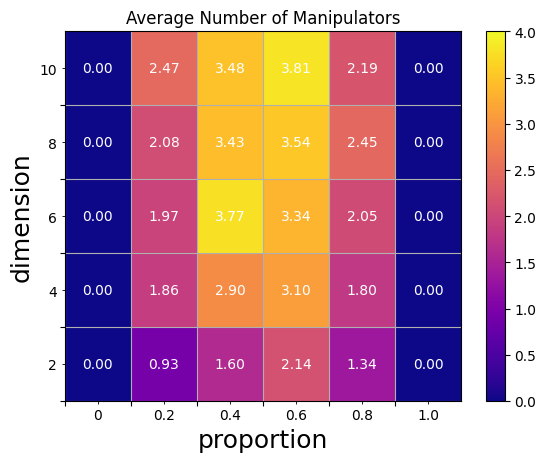

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

p_list = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list  = [2, 4, 6, 8, 10]
    
w_number = np.array(number_reverse_euclidean)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=4))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(p_list, minor=True)
ax.set_yticklabels(d_list, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('proportion', fontsize=18)
plt.ylabel('dimension', fontsize=18)
plt.title('Average Number of Manipulators')
plt.grid(True)

plt.savefig("accomplice_reverse_euclidean.pdf", format='pdf')
plt.show()

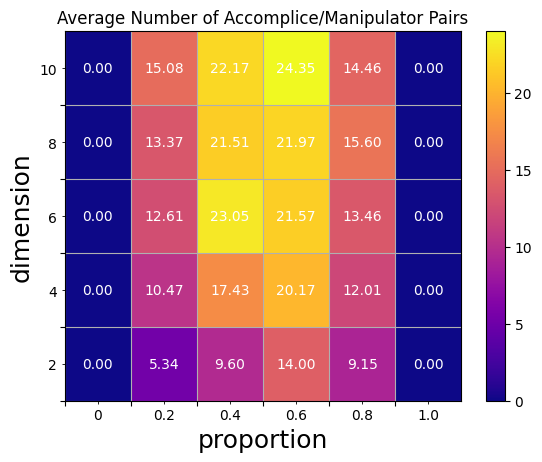

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

p_list = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list  = [2, 4, 6, 8, 10]
    
w_number = np.array(number_reverse_euclidean_pairs)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=24))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(p_list, minor=True)
ax.set_yticklabels(d_list, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('proportion', fontsize=18)
plt.ylabel('dimension', fontsize=18)
plt.title('Average Number of Accomplice/Manipulator Pairs')
plt.grid(True)

plt.savefig("accomplice_pairs_reverse_euclidean.pdf", format='pdf')
plt.show()

**Mallows MD**

In [14]:
##Mallows MD

data_MD = []
numberMD = []
numberMD_pairs = []
n=30
phi_list=[0, 0.2, 0.4, 0.6, 0.8, 1]
for phi1 in tqdm(phi_list):
    number_phi = []
    number_phi_pairs = []
    for phi2 in tqdm(phi_list):
        count = []
        count_pairs = []
        ct = []
        for samples in range (500):
            count_woman = 0
            cnt_pairs = 0
            pref=generate_mallows_asymmetric_votes(num_agents=n, phi_m=phi1, phi_w=phi2)
            mpref=pref[0]
            wpref=pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                cnt = 0
                for accomplice in range(1, n+1):
                    result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
                    if result [0]!= matching:
                        cnt = cnt+1
                if cnt >= 1:
                    count_woman += 1
                    cnt_pairs += cnt
            count_pairs.append(cnt_pairs)
            count.append(count_woman)
            data_MD.append([phi1, phi2, json.dumps(mpref), json.dumps(wpref), samples, count_woman, cnt_pairs])
        if len(count) > 0: 
            number_phi.append(sum(count) / len(count))
            number_phi_pairs.append(sum(count_pairs) / len(count_pairs))
        else:
            number_phi.append(0)
            number_phi_pairs.append(0)
    numberMD.append(number_phi)
    numberMD_pairs.append(number_phi_pairs) 
print(numberMD)
print(numberMD_pairs) 

100%|██████████| 6/6 [22:51:38<00:00, 13716.36s/it]  

[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [8.502, 5.92, 5.766, 4.624, 4.19, 3.32], [8.548, 7.608, 6.68, 6.506, 6.062, 5.546], [8.516, 8.436, 7.672, 8.002, 7.958, 6.3], [9.078, 8.968, 8.958, 8.644, 7.948, 6.708], [7.374, 6.736, 7.162, 7.08, 6.534, 6.696]]
[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [14.036, 9.548, 9.188, 8.826, 13.974, 22.668], [17.998, 17.074, 14.684, 16.234, 25.484, 35.11], [26.592, 25.776, 22.9, 25.81, 33.856, 42.892], [45.472, 44.426, 43.522, 41.48, 42.784, 37.902], [45.382, 42.726, 41.746, 38.588, 35.672, 35.2]]


In [16]:
df4 = pd.DataFrame(data_MD, columns=["phi_m", "phi_w", "mpref", "wpref", "sample", "count_woman", "cnt_pairs"])
df4.to_csv('mallows_MD_accomplice.csv', index=False)

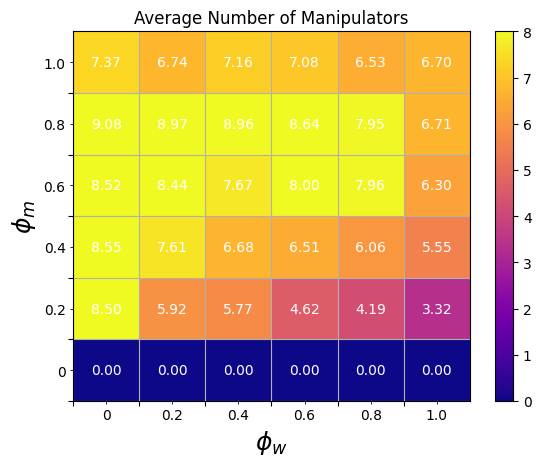

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0] 
    
w_number = np.array(numberMD)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=8))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Average Number of Manipulators')
plt.grid(True)

plt.savefig("accomplice_mallows_MD.pdf", format='pdf')
plt.show()

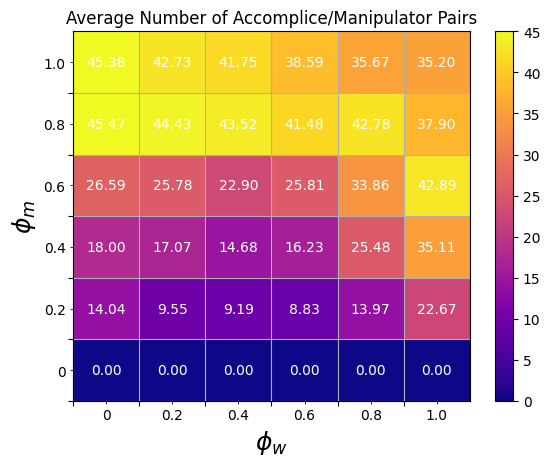

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0] 
    
w_number = np.array(numberMD_pairs)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=45))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Average Number of Accomplice/Manipulator Pairs')
plt.grid(True)

plt.savefig("accomplice_pairs_mallows_MD.pdf", format='pdf')
plt.show()

**Mallows**

In [22]:
##Mallows

numberM = []
numberM_pairs = []
data_M = []
n=30
phi_list=[0, 0.2, 0.4, 0.6, 0.8, 1]
for phi1 in tqdm(phi_list):
    number_phi = []
    number_phi_pairs = []
    for phi2 in tqdm(phi_list):
        count =[]
        count_pairs = []
        ct=[]
        for samples in range (500):
            count_woman = 0
            cnt_pairs = 0
            m_pref = [generate_ic_votes(n)[0]]*n
            w_pref = [generate_ic_votes(n)[0]]*n
            mpref= mallows_votes(m_pref, phi1)
            wpref= mallows_votes(w_pref, phi2)
            mpref_clean = [[int(x) for x in row] for row in mpref] #these two are for saving purposes
            wpref_clean = [[int(x) for x in row] for row in wpref]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                cnt = 0
                for accomplice in range (1, n+1):
                    result = accomplice_manipulation(mpref, wpref, manipulator, accomplice) 
                    if result [0]!= matching:
                        cnt = cnt+1
                if cnt >= 1:
                    count_woman += 1
                    cnt_pairs += cnt
            count.append(count_woman)
            count_pairs.append(cnt_pairs)
            data_M.append([phi1, phi2, json.dumps(mpref_clean), json.dumps(wpref_clean), samples, count_woman, cnt_pairs])
        if len(count)>0:
            number_phi.append(sum(count) / len(count))
            number_phi_pairs.append(sum(count_pairs) / len(count_pairs))
        else:
            number_phi.append(0)
            number_phi_pairs.append(0)
    numberM.append(number_phi)
    numberM_pairs.append(number_phi_pairs)
print(numberM)
print(numberM_pairs)

100%|██████████| 6/6 [25:53:03<00:00, 15530.57s/it]  

[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.1, 0.242, 0.376, 0.308, 0.188], [0.0, 0.226, 0.606, 0.722, 0.752, 0.366], [0.0, 0.282, 0.72, 1.214, 1.336, 1.178], [0.0, 0.22, 0.544, 1.308, 2.216, 3.028], [0.0, 0.074, 0.376, 1.04, 3.04, 6.36]]
[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.126, 0.32, 0.716, 1.324, 0.856], [0.0, 0.26, 0.968, 1.696, 2.942, 1.742], [0.0, 0.362, 1.296, 2.922, 5.528, 5.568], [0.0, 0.296, 1.192, 3.898, 10.358, 14.758], [0.0, 0.094, 0.792, 3.538, 16.258, 35.156]]


In [27]:
df5 = pd.DataFrame(data_M, columns=["phi_m", "phi_w", "mpref", "wpref", "sample", "count_woman", "cnt_pairs"])
df5.to_csv('mallows_accomplice.csv', index=False)

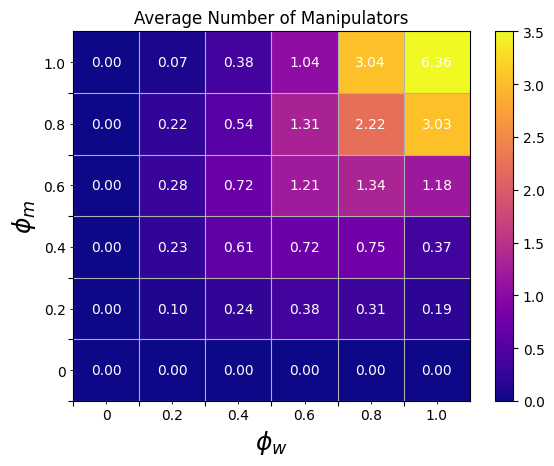

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0] 
numberM = [[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.1, 0.242, 0.376, 0.308, 0.188], [0.0, 0.226, 0.606, 0.722, 0.752, 0.366], [0.0, 0.282, 0.72, 1.214, 1.336, 1.178], [0.0, 0.22, 0.544, 1.308, 2.216, 3.028], [0.0, 0.074, 0.376, 1.04, 3.04, 6.36]]
    
w_number = np.array(numberM)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=3.5))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Average Number of Manipulators')
plt.grid(True)

plt.savefig("accomplice_mallows.pdf", format='pdf')
plt.show()

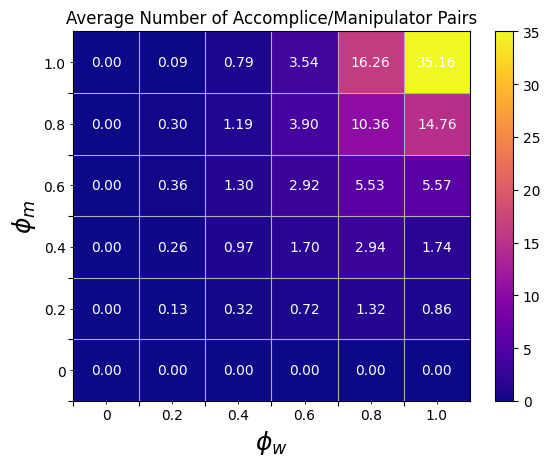

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0] 
    
w_number = np.array(numberM_pairs)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=35))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Average Number of Accomplice/Manipulator Pairs')
plt.grid(True)

plt.savefig("accomplice_pairs_mallows.pdf", format='pdf')
plt.show()

**Fame Euclidean**

In [5]:
# Fame Euclidean
data_FE = []
numberFE = []
numberFE_pairs = []
d_list = [2, 3, 5, 10]
f_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
n = 30
for d in tqdm(d_list):
    number_d = []
    number_d_pairs = []
    for f in tqdm(f_list):
        count = []
        count_pairs = []
        ct = []
        for samples in range(500):
            count_woman = 0
            cnt_pairs = 0
            pref = generate_fame_votes(n, d, 'uniform', f)
            mpref = pref[0]
            wpref = pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                cnt = 0
                for accomplice in range(1, n+1):
                    result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
                    if result[0] != matching:
                        cnt += 1
                if cnt >= 1:
                    count_woman += 1
                    cnt_pairs += cnt
            count_pairs.append(cnt_pairs)
            count.append(cnt)
            data_FE.append([d, f, json.dumps(mpref), json.dumps(wpref), samples, count_woman, cnt_pairs])
        if len(count) > 0:
            number_d.append(sum(count)/len(count))
            number_d_pairs.append(sum(count_pairs)/ len(count_pairs))
        else:
            number_d.append(0)
            number_d_pairs.append(0)
    numberFE.append(number_d)
    numberFE_pairs.append(number_d_pairs)
print(numberFE)
print(numberFE_pairs)

100%|██████████| 4/4 [2:26:36<00:00, 2199.24s/it]

[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]]
[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]]


In [6]:
df6 = pd.DataFrame(data_FE, columns=["dimension", "fame", "mpref", "wpref", "sample", "count_woman", "cnt_pairs"])
df6.to_csv('fame_euclidean_accomplice.csv', index=False)

**Expectations Euclidean**

In [8]:
import numpy as np

def convert_to_builtin(obj):
    if isinstance(obj, dict):
        return {convert_to_builtin(k): convert_to_builtin(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [convert_to_builtin(elem) for elem in obj]
    elif isinstance(obj, np.integer):
        return int(obj)
    elif isinstance(obj, np.floating):
        return float(obj)
    else:
        return obj

In [22]:
import numpy as np

def generate_expectation_votes(num_agents: int = None,
                               dim: int = None,
                               space='uniform',
                               std: float = None,
                               phi=0.5,
                               **kwargs):
    name = f'{dim}d_{space}'

    left_agents_reality = np.array([get_uniform_point(dim) for _ in range(num_agents)])
    left_agents_wishes = np.zeros([num_agents, dim])

    right_agents_reality = np.array([get_uniform_point(dim) for _ in range(num_agents)])
    right_agents_wishes = np.zeros([num_agents, dim])

    for v in range(num_agents):
        # while agents_wishes[v][0] <= 0 or agents_wishes[v][0] >= 1:
        left_agents_wishes[v][0] = np.random.normal(left_agents_reality[v][0], std)
        # while agents_wishes[v][1] <= 0 or agents_wishes[v][1] >= 1:
        left_agents_wishes[v][1] = np.random.normal(left_agents_reality[v][1], std)

        # while agents_wishes[v][0] <= 0 or agents_wishes[v][0] >= 1:
        right_agents_wishes[v][0] = np.random.normal(right_agents_reality[v][0], std)
        # while agents_wishes[v][1] <= 0 or agents_wishes[v][1] >= 1:
        right_agents_wishes[v][1] = np.random.normal(right_agents_reality[v][1], std)

    left_votes = np.zeros([num_agents, num_agents], dtype=int)
    right_votes = np.zeros([num_agents, num_agents], dtype=int)
    distances = np.zeros([num_agents, num_agents], dtype=float)

    for v in range(num_agents):
        for c in range(num_agents):
            left_votes[v][c] = c
            distances[v][c] = np.linalg.norm(right_agents_reality[c] - left_agents_wishes[v])
        left_votes[v] = [x for _, x in sorted(zip(distances[v], left_votes[v]))]

    for v in range(num_agents):
        for c in range(num_agents):
            right_votes[v][c] = c
            distances[v][c] = np.linalg.norm(left_agents_reality[c] - right_agents_wishes[v])
        right_votes[v] = [x for _, x in sorted(zip(distances[v], right_votes[v]))]

    left_votes_lst = [list(row) for row in left_votes]
    right_votes_lst = [list(row) for row in right_votes]


    for i in range(len(left_votes_lst)):
        for j in range(len(left_votes_lst[i])):
            left_votes_lst[i][j] = left_votes_lst[i][j] + 1
    for i in range(len(right_votes_lst)):
        for j in range(len(right_votes_lst[i])):
            right_votes_lst[i][j] = right_votes_lst[i][j] + 1

    return [left_votes_lst, right_votes_lst]

In [24]:
## Expectations Euclidean

data_EE = []
number_expectations_euclidean = []
number_EE_pairs = []
n = 30
std_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list = [2, 4, 6, 8, 10]

for d in tqdm(d_list):
    number_d = []
    number_d_pairs = []
    for std in tqdm(std_list):
        count = []
        count_pairs = []
        ct = []
        for samples in range(500):
            count_woman = 0
            cnt_pairs = 0
            pref = generate_expectation_votes(n, d, 'uniform', std, 0.5)
            mpref = pref[0]
            wpref = pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                cnt = 0
                for accomplice in range (1, n+1):
                    result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
                    if result[0] != matching:
                        cnt += 1
                if cnt >= 1:
                    count_woman += 1
                    cnt_pairs += cnt
            count.append(count_woman)
            count_pairs.append(cnt_pairs)
            data_EE.append([d, std, json.dumps(convert_to_builtin(mpref)), json.dumps(convert_to_builtin(wpref)), samples, count_woman, cnt_pairs])
        if len(count) > 0:
            number_d.append(sum(count)/len(count))
            number_d_pairs.append(sum(count_pairs)/ len(count_pairs))
        else:
            number_d.append(0)
            number_d_pairs.append(0)
    number_expectations_euclidean.append(number_d)
    number_EE_pairs.append(number_d_pairs)
print(number_expectations_euclidean)
print(number_EE_pairs)

100%|██████████| 5/5 [26:34:52<00:00, 19138.47s/it]  

[[0.0, 2.262, 3.66, 3.0, 2.924, 2.626], [0.0, 0.378, 0.87, 1.206, 1.372, 1.502], [0.0, 0.304, 0.686, 0.86, 1.234, 1.312], [0.0, 0.26, 0.644, 0.992, 0.994, 1.068], [0.0, 0.192, 0.592, 0.842, 0.982, 1.012]]
[[0.0, 9.432, 20.312, 18.926, 16.492, 14.436], [0.0, 0.76, 2.894, 4.298, 5.844, 7.454], [0.0, 0.606, 1.914, 2.676, 5.334, 5.96], [0.0, 0.48, 1.638, 2.952, 3.378, 4.384], [0.0, 0.332, 1.424, 2.454, 3.268, 3.406]]


In [26]:
df6 = pd.DataFrame(data_EE, columns=["dimension", "std", "mpref", "wpref", "sample", "count_woman", "cnt_pairs"])
df6.to_csv('expectations_euclidean_accomplice.csv', index=False)

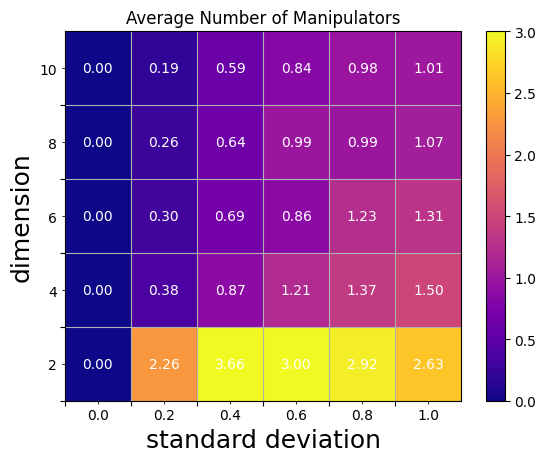

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

std_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list = [2, 4, 6, 8, 10]
    
w_number = np.array(number_expectations_euclidean)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=3))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(std_list, minor=True)
ax.set_yticklabels(d_list, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('standard deviation', fontsize=18)
plt.ylabel('dimension', fontsize=18)
plt.title('Average Number of Manipulators')
plt.grid(True)

plt.savefig("accomplice_expectations_euclidean.pdf", format='pdf')
plt.show()

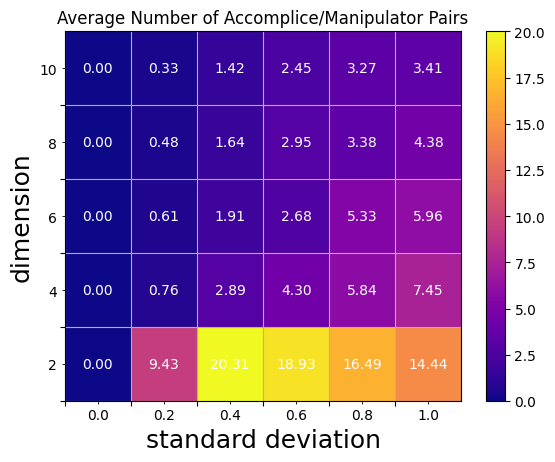

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

std_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list = [2, 4, 6, 8, 10]
    
w_number = np.array(number_EE_pairs)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=20))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(std_list, minor=True)
ax.set_yticklabels(d_list, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('standard deviation', fontsize=18)
plt.ylabel('dimension', fontsize=18)
plt.title('Average Number of Accomplice/Manipulator Pairs')
plt.grid(True)

plt.savefig("accomplice_pairs_expectations_euclidean.pdf", format='pdf')
plt.show()